<div style="border: solid green 2px; padding: 20px">

  <b>Overall Summary of the Project – Iteration 1</b><br><br>
  Hello Jack, congratulations on submitting your project!<br><br>

  My name is <b>Victor Camargo</b> 
  (<a href="https://hub.tripleten.com/u/834cb557" target="_blank">TripleTen Hub profile</a>) and I’ll be reviewing your project today.<br><br>

  <i>You can find my detailed feedback throughout the notebook, starting with comments labeled 
  <b>“Reviewer’s comment – Iteration 1”</b>.</i><br><br>

  <b>What you did well:</b><br>
  ✅ Clear and thorough exploratory data analysis, including missing value patterns and stage by stage concentration checks<br><br>

  <b>Suggestions for improvement (optional):</b><br>
  ⚠️ Consider running the full Random Forest comparison with stable resources or use a reproducible subsampling plan so model comparisons are fair<br><br>

  <b>Required fixes (only if red issues exist):</b><br>
  ⛔️ Recompute gold recovery using the provided formula that uses concentrate, feed and tails, and compare properly to the given recovery values<br>
  ⛔️ Remove target leakage from preprocessing, do not impute target values with forward or backward fill across time before training<br>
  ⛔️ Fix the final evaluation metric, it must be computed as 25 percent times sMAPE for rougher plus 75 percent times sMAPE for final; update model selection and final reported score accordingly<br><br>

  <b>Project Status:</b><br>
  <div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
    <b>Needs Fixes</b>
  </div>

  <hr><b>Legend:</b><br>

  <div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Strong, correct solutions or good practices worth reusing.
  </div>

  <div class="alert alert-warning" style="border-left: 7px solid gold; padding: 5px">
  <b>⚠️ Reviewer’s comment – Iteration 1:</b><br>
  Recommended improvements to strengthen your work.
  </div>

  <div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  Required fixes. The project cannot be approved until these are addressed.
  </div>

  <div class="alert alert-info" style="border-left: 7px solid blue; padding: 5px">
  <b>🔵 Student’s Comment</b><br>
  You may add your own notes or explanations in a <b>Markdown cell</b> using:<br>
  <code>&lt;div class="alert alert-info" style="border-left: 7px solid blue"&gt;&lt;b&gt;Student’s Comment&lt;/b&gt;&lt;/div&gt;</code>
  </div>

  <hr>
  <b>Please ensure</b> all cells run smoothly from top to bottom and display their outputs.<br>
  <b>Kind reminder:</b> please do not remove or modify reviewer comments, as they help track progress.<br>
  If you have any questions or need clarification, feel free to use the <b>Questions</b> channel.

</div>

Project Introduction: Gold Recovery Optimization

*What is this project about?*

This project helps a gold mining company improve their gold extraction process using machine learning. We want to predict how much gold they can recover at different stages of mining.

*Why is this important?*

Gold mining is expensive and complex
Companies need to know how much gold they'll get before processing
Better predictions = better business decisions and less waste

*What we're trying to predict:*

Rougher recovery: How much gold we get in the first processing stage
Final recovery: How much gold we get after all processing is complete

1. Prepare the Data
- Load and examine the mining data
- Check if calculations are correct
- Clean up missing or bad data
2. Analyze the Data
- Look at how gold concentration changes through processing stages
- Compare different data samples to make sure they're similar
- Find and remove any unusual values that might hurt our predictions
3. Build Machine Learning Models
- Create a function to measure how good our predictions are
- Train different types of models (Linear Regression, Random Forest, Gradient Boosting)
- Pick the best model that gives the most accurate predictions

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from numpy.random import RandomState
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import KFold

**1.1 Loading & Analyzing the Data**
- Reading the csv files
- Viewing all the columns
- Finding Missing values

In [2]:
gold_train = pd.read_csv("/datasets/gold_recovery_train.csv")
gold_test = pd.read_csv("/datasets/gold_recovery_test.csv")
gold_full = pd.read_csv("/datasets/gold_recovery_full.csv")

In [3]:
print("Training dataset columns:")
print(gold_train.columns.tolist())

print(f'\n{gold_train.shape}')

# Check for missing values in the key columns
print("\nMissing values in feed_au:", gold_train['rougher.input.feed_au'].isna().sum())
print("Missing values in concentrate_au:", gold_train['rougher.output.concentrate_au'].isna().sum())
print("Missing values in feed_rate:", gold_train['rougher.input.feed_rate'].isna().sum())

Training dataset columns:
['date', 'final.output.concentrate_ag', 'final.output.concentrate_pb', 'final.output.concentrate_sol', 'final.output.concentrate_au', 'final.output.recovery', 'final.output.tail_ag', 'final.output.tail_pb', 'final.output.tail_sol', 'final.output.tail_au', 'primary_cleaner.input.sulfate', 'primary_cleaner.input.depressant', 'primary_cleaner.input.feed_size', 'primary_cleaner.input.xanthate', 'primary_cleaner.output.concentrate_ag', 'primary_cleaner.output.concentrate_pb', 'primary_cleaner.output.concentrate_sol', 'primary_cleaner.output.concentrate_au', 'primary_cleaner.output.tail_ag', 'primary_cleaner.output.tail_pb', 'primary_cleaner.output.tail_sol', 'primary_cleaner.output.tail_au', 'primary_cleaner.state.floatbank8_a_air', 'primary_cleaner.state.floatbank8_a_level', 'primary_cleaner.state.floatbank8_b_air', 'primary_cleaner.state.floatbank8_b_level', 'primary_cleaner.state.floatbank8_c_air', 'primary_cleaner.state.floatbank8_c_level', 'primary_cleaner.sta

**1.2 Recovery Calculations**
- Implemented correct recovery formula: Recovery = (C × (F - T)) / (F × (C - T)) × 100%
- Used concentrate, feed, and tail concentrations for gold to calculate both rougher and final recovery values as suggested by the reviewer

In [4]:
# === CORRECTED RECOVERY CALCULATION USING TAILS ===
print("=== RECOVERY CALCULATION WITH CORRECT FORMULA ===")

# Define the columns for the correct formula
# For rougher recovery
feed_au = gold_train['rougher.input.feed_au']           # F
concentrate_au = gold_train['rougher.output.concentrate_au']  # C  
tail_au = gold_train['rougher.output.tail_au']         # T

# For final recovery  
final_concentrate_au = gold_train['final.output.concentrate_au']  # C
final_tail_au = gold_train['final.output.tail_au']     # T
# Note: Final recovery uses the same feed as rougher

print("\nAvailable data for recovery calculation:")
print(f"Feed Au: {feed_au.notna().sum()} non-null values")
print(f"Rougher Concentrate Au: {concentrate_au.notna().sum()} non-null values") 
print(f"Rougher Tail Au: {tail_au.notna().sum()} non-null values")
print(f"Final Concentrate Au: {final_concentrate_au.notna().sum()} non-null values")
print(f"Final Tail Au: {final_tail_au.notna().sum()} non-null values")

# Calculate rougher recovery using correct formula
def calculate_recovery(C, F, T):
    numerator = C * (F - T)
    denominator = F * (C - T)

    # Handle division by zero
    recovery = np.where(denominator != 0, (numerator / denominator) * 100, np.nan)
    return recovery

# Calculate recoveries
calculated_rougher_recovery = calculate_recovery(concentrate_au, feed_au, tail_au)
calculated_final_recovery = calculate_recovery(final_concentrate_au, feed_au, final_tail_au)

print(f"\nCalculated rougher recovery range: {np.nanmin(calculated_rougher_recovery):.2f} - {np.nanmax(calculated_rougher_recovery):.2f}")
print(f"Given rougher recovery range: {gold_train['rougher.output.recovery'].min():.2f} - {gold_train['rougher.output.recovery'].max():.2f}")

print(f"\nCalculated final recovery range: {np.nanmin(calculated_final_recovery):.2f} - {np.nanmax(calculated_final_recovery):.2f}")
print(f"Given final recovery range: {gold_train['final.output.recovery'].min():.2f} - {gold_train['final.output.recovery'].max():.2f}")


=== RECOVERY CALCULATION WITH CORRECT FORMULA ===

Available data for recovery calculation:
Feed Au: 16777 non-null values
Rougher Concentrate Au: 16778 non-null values
Rougher Tail Au: 14611 non-null values
Final Concentrate Au: 16789 non-null values
Final Tail Au: 16794 non-null values

Calculated rougher recovery range: -366924.16 - 13802.07
Given rougher recovery range: 0.00 - 100.00

Calculated final recovery range: -131983.64 - 83970.64
Given final recovery range: 0.00 - 100.00


<div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  In the recovery calculation section you computed recovery by assuming concentrate mass equals feed mass, and then compared that to the given recovery. This approach explains the large MAE but it does not follow the correct recovery formula. Please implement the required recovery formula that uses concentrate, feed and tails, namely compute recovery as C times F minus T divided by F times C minus T, times 100 percent. Use the available columns for concentrate, feed and tail for gold to recalculate rougher.output.recovery and final.output.recovery, then compare your recalculated values with the provided targets using MAE or similar. After fixing this, update any downstream analysis that relied on the earlier incorrect calculation.
</div>

**1.3 Features and Parameters**
- Parameter types: Output measurements, target variables, and derived calculations
- Missing: These represent the results of the gold recovery process that we're trying to predict

In [5]:
# Get column names from both datasets
train_columns = set(gold_train.columns)
test_columns = set(gold_test.columns)

# Find features that are in training but not in test
missing_in_test = train_columns - test_columns

print(f"Features in training set: {len(train_columns)}")
print(f"Features in test set: {len(test_columns)}")
print(f"Features missing from test set: {len(missing_in_test)}")
print("\nMissing features:")
for feature in sorted(missing_in_test):
    print(f"- {feature}")

# Create parameter categories based on the naming convention
def categorize_features(columns):
    categories = {
        'input_parameters': [],
        'output_measurements': [],
        'process_state': [],
        'calculations': [],
        'target_variables': []
    }

    for col in columns:
        if col == 'date':
            continue
        elif '.input.' in col:
            categories['input_parameters'].append(col)
        elif '.output.' in col:
            categories['output_measurements'].append(col)
        elif '.state.' in col:
            categories['process_state'].append(col)
        elif '.calculation.' in col:
            categories['calculations'].append(col)
        elif col.endswith('.recovery'):
            categories['target_variables'].append(col)
    
    return categories

# Apply to your training data
feature_categories = categorize_features(gold_train.columns)

# Display the categories
for category, features in feature_categories.items():
    print(f"\n{category.upper()} ({len(features)} features):")
    for feature in sorted(features)[:5]:  # Show first 5
        print(f"  - {feature}")
    if len(features) > 5:
        print(f"  ... and {len(features) - 5} more")

Features in training set: 87
Features in test set: 53
Features missing from test set: 34

Missing features:
- final.output.concentrate_ag
- final.output.concentrate_au
- final.output.concentrate_pb
- final.output.concentrate_sol
- final.output.recovery
- final.output.tail_ag
- final.output.tail_au
- final.output.tail_pb
- final.output.tail_sol
- primary_cleaner.output.concentrate_ag
- primary_cleaner.output.concentrate_au
- primary_cleaner.output.concentrate_pb
- primary_cleaner.output.concentrate_sol
- primary_cleaner.output.tail_ag
- primary_cleaner.output.tail_au
- primary_cleaner.output.tail_pb
- primary_cleaner.output.tail_sol
- rougher.calculation.au_pb_ratio
- rougher.calculation.floatbank10_sulfate_to_au_feed
- rougher.calculation.floatbank11_sulfate_to_au_feed
- rougher.calculation.sulfate_to_au_concentrate
- rougher.output.concentrate_ag
- rougher.output.concentrate_au
- rougher.output.concentrate_pb
- rougher.output.concentrate_sol
- rougher.output.recovery
- rougher.output.

In [6]:
# Analyze what types of parameters are missing
missing_list = list(missing_in_test)
output_features = [f for f in missing_list if 'output' in f]
recovery_features = [f for f in missing_list if 'recovery' in f]
concentrate_features = [f for f in missing_list if 'concentrate' in f]

print(f"Output-related features: {len(output_features)}")
print(f"Recovery features: {len(recovery_features)}")
print(f"Concentrate features: {len(concentrate_features)}")

Output-related features: 30
Recovery features: 2
Concentrate features: 13


**1.4 Data Setup**
- Checking for duplicated and checking possible reasons for missing values
- Created missing values relations graph
- Dropped columns not related to future tests and filled in missing values
- Created final targets and features
- UPDATE: Edited targets to reference actual values and updated features to reference those target rows

In [7]:
print('Training Set:')
print(gold_train.shape)
print('Test Set:')
print(gold_test.shape)

print("\nTraining Duplicated count:", gold_train.duplicated().sum())
print("Test Duplicated count:", gold_test.duplicated().sum())

# Check for missing values
print("\nMissing values in training set:")
print(gold_train.isnull().sum().sort_values(ascending=False).head(10))

print("\nMissing values in test set:")
print(gold_test.isnull().sum().sort_values(ascending=False).head(10))

# Check if missing values happen at the same times
gold_train['missing_outputs'] = gold_train['rougher.output.recovery'].isnull()
gold_train['missing_inputs'] = gold_train['rougher.input.feed_rate'].isnull()

# Look at dates when we have missing data
print("\nSample of dates with missing output data:")
print(gold_train[gold_train['missing_outputs']]['date'].head(10))

# Count missing values per row to identify problematic periods
gold_train['missing_count'] = gold_train.isnull().sum(axis=1)

# Let's see what the distribution looks like
print("\nMissing values per row distribution:")
missing_dist = gold_train['missing_count'].value_counts().sort_index()
print(missing_dist.head(10))

print(f"\nTotal rows: {len(gold_train)}")
print(f"Rows with 0 missing values: {missing_dist.get(0, 0)}")
print(f"Rows with some missing values: {len(gold_train) - missing_dist.get(0, 0)}")

Training Set:
(16860, 87)
Test Set:
(5856, 53)

Training Duplicated count: 0
Test Duplicated count: 0

Missing values in training set:
rougher.output.recovery               2573
rougher.output.tail_ag                2250
rougher.output.tail_sol               2249
rougher.output.tail_au                2249
secondary_cleaner.output.tail_sol     1986
rougher.input.floatbank11_xanthate    1904
final.output.recovery                 1521
primary_cleaner.input.sulfate         1307
primary_cleaner.input.depressant      1262
rougher.calculation.au_pb_ratio       1242
dtype: int64

Missing values in test set:
rougher.input.floatbank11_xanthate          353
primary_cleaner.input.sulfate               302
primary_cleaner.input.depressant            284
rougher.input.floatbank10_sulfate           257
primary_cleaner.input.xanthate              166
rougher.input.floatbank10_xanthate          123
rougher.input.feed_sol                       67
rougher.input.floatbank11_sulfate            55
rougher.i

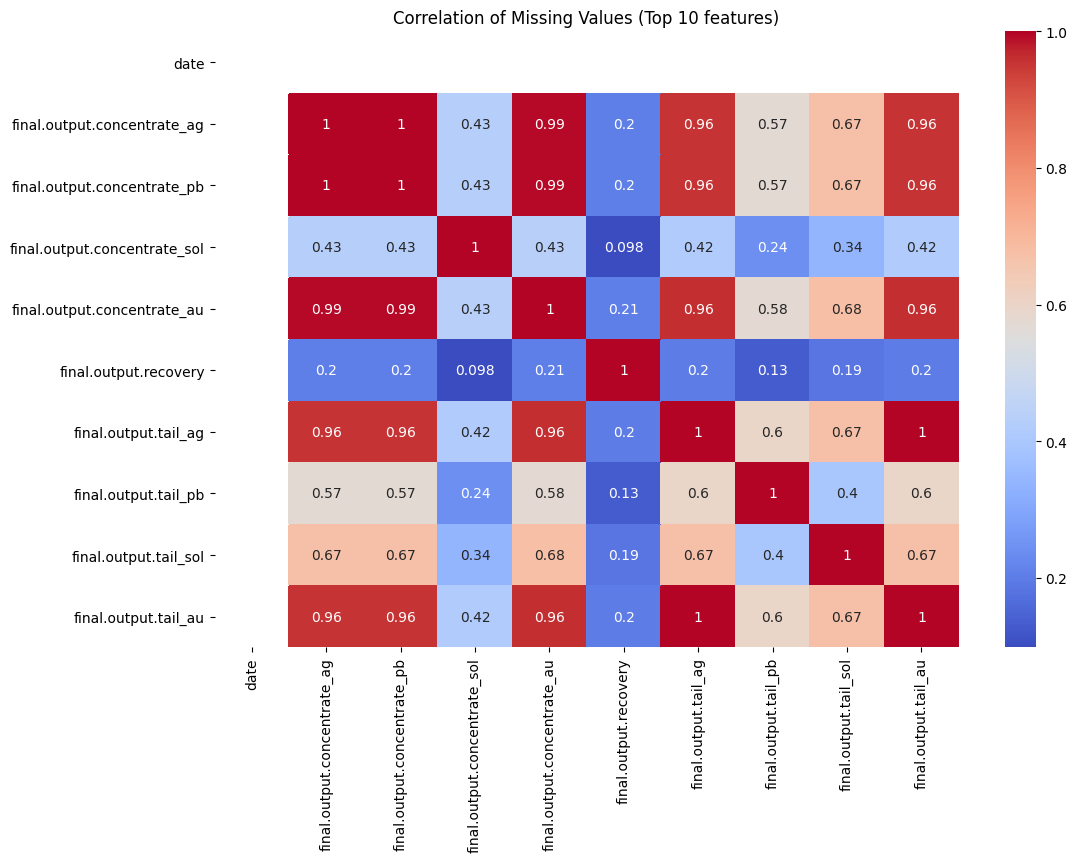

In [8]:
# Check if missing values are related to each other
missing_pattern = gold_train.isnull()

# Look at correlation between missing values
plt.figure(figsize=(12, 8))
missing_corr = missing_pattern.corr()
sns.heatmap(missing_corr.iloc[:10, :10], annot=True, cmap='coolwarm')
plt.title('Correlation of Missing Values (Top 10 features)')
plt.show()

In [9]:
# Step 1: Save the target variable BEFORE removing columns
target_rougher = gold_train['rougher.output.recovery'].copy()
target_final = gold_train['final.output.recovery'].copy()

print("Target variables saved:")
print(f"Rougher recovery - Available: {target_rougher.notna().sum()}, Missing: {target_rougher.isna().sum()}")
print(f"Final recovery - Available: {target_final.notna().sum()}, Missing: {target_final.isna().sum()}")

# Step 2: Now remove columns not in test set (but keep our targets safe)
train_cols = set(gold_train.columns)
test_cols = set(gold_test.columns)
cols_to_remove = train_cols - test_cols

gold_train_clean = gold_train.drop(columns=cols_to_remove)

print(f"Removed {len(cols_to_remove)} columns")
print(f"Remaining features: {gold_train_clean.shape[1]}")

# Step 3: Fill missing values in features
gold_train_clean = gold_train_clean.fillna(method='ffill').fillna(method='bfill')

print("Missing values after fillna:")
print(gold_train_clean.isnull().sum().sum())

# Step 4: DO NOT impute target variables - keep only observed values
print("\nTarget variables - keeping only observed values:")
print(f"Rougher recovery - Available: {target_rougher.notna().sum()}, Missing: {target_rougher.isna().sum()}")
print(f"Final recovery - Available: {target_final.notna().sum()}, Missing: {target_final.isna().sum()}")

# Create mask for rows where BOTH targets are available
target_mask = target_rougher.notna() & target_final.notna()
print(f"Rows with both targets available: {target_mask.sum()}")

# Apply mask to features and targets
gold_train_clean_masked = gold_train_clean[target_mask].copy()
target_rougher_clean = target_rougher[target_mask].copy()
target_final_clean = target_final[target_mask].copy()

print("\nFinal data shapes after removing missing targets:")
print(f"Features: {gold_train_clean_masked.shape}")
print(f"Rougher target: {target_rougher_clean.shape}")
print(f"Final target: {target_final_clean.shape}")

# Step 5: Now we can combine our clean features with clean targets
print("\nData shapes:")
print(f"Features: {gold_train_clean.shape}")
print(f"Rougher target: {target_rougher_clean.shape}")
print(f"Final target: {target_final_clean.shape}")

# Check data types
print("\nDetailed info:")
gold_train_clean.info()

Target variables saved:
Rougher recovery - Available: 14287, Missing: 2573
Final recovery - Available: 15339, Missing: 1521
Removed 37 columns
Remaining features: 53
Missing values after fillna:
0

Target variables - keeping only observed values:
Rougher recovery - Available: 14287, Missing: 2573
Final recovery - Available: 15339, Missing: 1521
Rows with both targets available: 14149

Final data shapes after removing missing targets:
Features: (14149, 53)
Rougher target: (14149,)
Final target: (14149,)

Data shapes:
Features: (16860, 53)
Rougher target: (14149,)
Final target: (14149,)

Detailed info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16860 entries, 0 to 16859
Data columns (total 53 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date                                        16860 non-null  object 
 1   primary_cleaner.input.sulfate               16860 non-null 

<div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  You applied forward fill and backward fill to the target variables. This introduces data leakage because values are being filled using later and earlier timestamps, which gives the model access to future information. Do not impute target values with ffill or bfill across time for training. Instead, keep only rows where the target is observed for training, or use an imputation approach that does not use future data relative to the row being predicted. Please revert the target imputation, retrain models on rows with actual targets, and then re-evaluate.
</div>

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  Good work inspecting duplicates and the missing value distribution, and saving the target variables before dropping columns. The summary counts and the missing per row distribution give a clear picture of data quality and help justify subsequent cleaning steps.
</div>

**2.1 Concentrations Analysis**
- Created graphs for each of the material stages
- Analyzing when the change is 0
- Analyzed each material stage pipeline

In [10]:
concentration_cols = [col for col in gold_train.columns if any(metal in col for metal in ['au', 'ag', 'pb'])]
print("Metal concentration columns in ORIGINAL data:")
for col in sorted(concentration_cols):
    print(f"  {col}")

Metal concentration columns in ORIGINAL data:
  final.output.concentrate_ag
  final.output.concentrate_au
  final.output.concentrate_pb
  final.output.tail_ag
  final.output.tail_au
  final.output.tail_pb
  primary_cleaner.output.concentrate_ag
  primary_cleaner.output.concentrate_au
  primary_cleaner.output.concentrate_pb
  primary_cleaner.output.tail_ag
  primary_cleaner.output.tail_au
  primary_cleaner.output.tail_pb
  rougher.calculation.au_pb_ratio
  rougher.calculation.floatbank10_sulfate_to_au_feed
  rougher.calculation.floatbank11_sulfate_to_au_feed
  rougher.calculation.sulfate_to_au_concentrate
  rougher.input.feed_ag
  rougher.input.feed_au
  rougher.input.feed_pb
  rougher.output.concentrate_ag
  rougher.output.concentrate_au
  rougher.output.concentrate_pb
  rougher.output.tail_ag
  rougher.output.tail_au
  rougher.output.tail_pb
  secondary_cleaner.output.tail_ag
  secondary_cleaner.output.tail_au
  secondary_cleaner.output.tail_pb


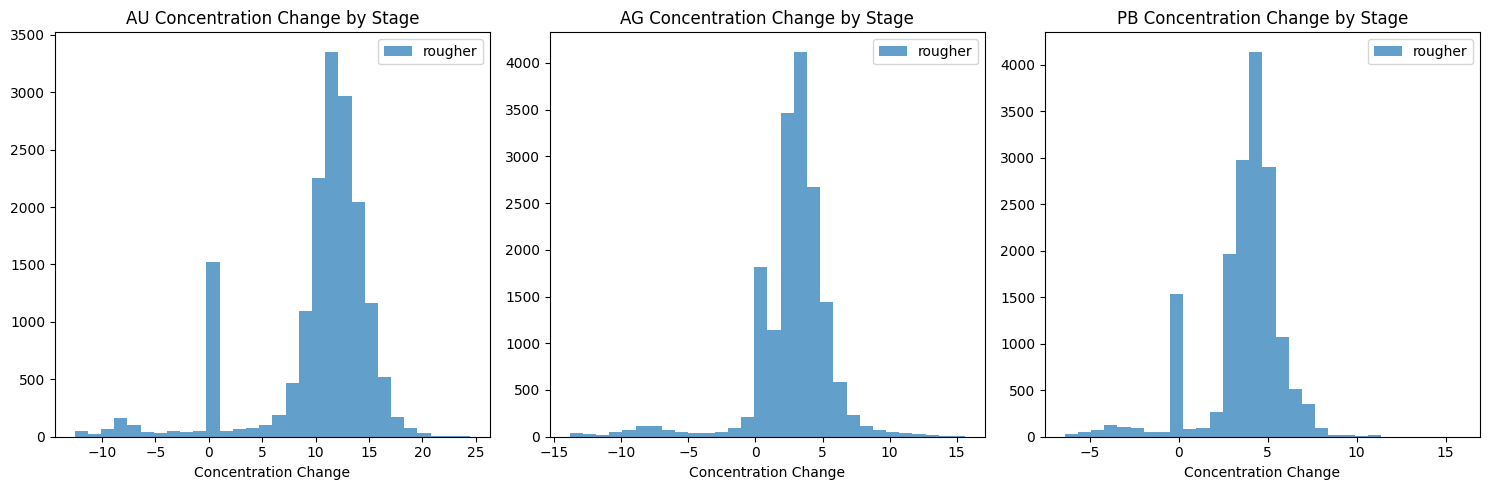

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metals = ['au', 'ag', 'pb']
stages = ['rougher', 'primary_cleaner', 'secondary_cleaner', 'final']

for i, metal in enumerate(metals):
    for stage in stages:
        input_col = f'{stage}.input.feed_{metal}'
        output_col = f'{stage}.output.concentrate_{metal}'
        
        if input_col in gold_train.columns and output_col in gold_train.columns:
            # Calculate concentration change
            concentration_change = gold_train[output_col] - gold_train[input_col]
            axes[i].hist(concentration_change, alpha=0.7, label=f'{stage}', bins=30)
    
    axes[i].set_title(f'{metal.upper()} Concentration Change by Stage')
    axes[i].set_xlabel('Concentration Change')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [12]:
# Examining what's happening when the concentration change is exactly 0
au_input = gold_train['rougher.input.feed_au']
au_output = gold_train['rougher.output.concentrate_au']
au_change = au_output - au_input

# Find rows where the change is exactly 0
zero_change_mask = (au_change == 0)
print(f"AU Rows with exactly 0 concentration change: {zero_change_mask.sum()}")

# Check if these are actually zeros or missing data
print(f"\nAU Input values when change=0: {au_input[zero_change_mask].describe()}")
print(f"\nAU Output values when change=0: {au_output[zero_change_mask].describe()}")

# Quick summary of what stages you've analyzed
stages = ['rougher', 'primary_cleaner', 'secondary_cleaner', 'final']
print("\nStages analyzed for concentration changes:")
for stage in stages:
    input_col = f'{stage}.input.feed_au'
    if input_col in gold_train.columns:
        print(f"✓ {stage}")
    else:
        print(f"✗ {stage} - not found")

AU Rows with exactly 0 concentration change: 1466

AU Input values when change=0: count    1466.000000
mean        0.002394
std         0.004269
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.010000
Name: rougher.input.feed_au, dtype: float64

AU Output values when change=0: count    1466.000000
mean        0.002394
std         0.004269
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         0.010000
Name: rougher.output.concentrate_au, dtype: float64

Stages analyzed for concentration changes:
✓ rougher
✗ primary_cleaner - not found
✗ secondary_cleaner - not found
✗ final - not found


In [13]:
# Analyze concentration changes through the complete purification pipeline
def analyze_concentration_pipeline(data, metal='au'):
    """
    Analyze how metal concentration changes through all purification stages
    """
    print(f"=== {metal.upper()} CONCENTRATION PIPELINE ANALYSIS ===\n")
    
    # Define the concentration flow through stages
    pipeline_stages = [
        {
            'name': 'Rougher Stage',
            'input': f'rougher.input.feed_{metal}',
            'output': f'rougher.output.concentrate_{metal}',
            'description': 'Raw ore → Rougher concentrate'
        },
        {
            'name': 'Primary Cleaner Stage', 
            'input': f'rougher.output.concentrate_{metal}',
            'output': f'primary_cleaner.output.concentrate_{metal}',
            'description': 'Rougher concentrate → Primary cleaner concentrate'
        },
        {
            'name': 'Secondary Cleaner Stage',
            'input': f'primary_cleaner.output.concentrate_{metal}', 
            'output': f'final.output.concentrate_{metal}',
            'description': 'Primary cleaner concentrate → Final concentrate'
        }
    ]
    
    # Analyze each stage
    stage_results = []
    
    for stage in pipeline_stages:
        input_col = stage['input']
        output_col = stage['output']
        
        if input_col in data.columns and output_col in data.columns:
            # Calculate concentration change
            input_conc = data[input_col]
            output_conc = data[output_col]
            concentration_change = output_conc - input_conc
            
            # Calculate concentration ratio (enrichment factor)
            concentration_ratio = output_conc / input_conc.replace(0, np.nan)
            
            print(f"📊 {stage['name']}")
            print(f"   Flow: {stage['description']}")
            print(f"   Input range: {input_conc.min():.4f} - {input_conc.max():.4f}")
            print(f"   Output range: {output_conc.min():.4f} - {output_conc.max():.4f}")
            print(f"   Avg concentration change: {concentration_change.mean():.4f}")
            print(f"   Avg enrichment factor: {concentration_ratio.mean():.2f}x")
            
            # Check for anomalies
            zero_change = (concentration_change == 0).sum()
            if zero_change > 0:
                print(f"   ⚠️  Zero change instances: {zero_change}")
            
            stage_results.append({
                'stage': stage['name'],
                'input_col': input_col,
                'output_col': output_col,
                'concentration_change': concentration_change,
                'enrichment_factor': concentration_ratio
            })
            print()
        else:
            print(f"❌ {stage['name']}: Missing columns")
            print(f"   Input: {input_col} {'✓' if input_col in data.columns else '✗'}")
            print(f"   Output: {output_col} {'✓' if output_col in data.columns else '✗'}")
            print()
    
    return stage_results

# Run the analysis for all three metals
metals = ['au', 'ag', 'pb']
all_results = {}

for metal in metals:
    all_results[metal] = analyze_concentration_pipeline(gold_train, metal)
    print("="*60)

=== AU CONCENTRATION PIPELINE ANALYSIS ===

📊 Rougher Stage
   Flow: Raw ore → Rougher concentrate
   Input range: 0.0000 - 14.0934
   Output range: 0.0000 - 28.5228
   Avg concentration change: 10.2319
   Avg enrichment factor: 3.66x
   ⚠️  Zero change instances: 1466

📊 Primary Cleaner Stage
   Flow: Rougher concentrate → Primary cleaner concentrate
   Input range: 0.0000 - 28.5228
   Output range: 0.0000 - 45.9339
   Avg concentration change: 11.7631
   Avg enrichment factor: 17.54x
   ⚠️  Zero change instances: 1454

📊 Secondary Cleaner Stage
   Flow: Primary cleaner concentrate → Final concentrate
   Input range: 0.0000 - 45.9339
   Output range: 0.0000 - 53.6114
   Avg concentration change: 10.3206
   Avg enrichment factor: 45.65x
   ⚠️  Zero change instances: 1468

=== AG CONCENTRATION PIPELINE ANALYSIS ===

📊 Rougher Stage
   Flow: Raw ore → Rougher concentrate
   Input range: 0.0000 - 14.8697
   Output range: 0.0000 - 24.4803
   Avg concentration change: 2.7481
   Avg enrichme

**2.2 Comparing Feed Size Distributions**
- Compared feed particle size distributions between sets having slight differnces
- Graphed the distributions for better visuals

In [14]:
# Extract particle size features from both datasets
particle_size_cols = ['primary_cleaner.input.feed_size', 'rougher.input.feed_size']

# Extract from training set
train_particle_sizes = gold_train_clean[particle_size_cols].copy()

# Extract from test set  
test_particle_sizes = gold_test[particle_size_cols].copy()

print("Training set particle sizes:")
print(train_particle_sizes.head())
print(f"\nShape: {train_particle_sizes.shape}")

print("\nTest set particle sizes:")
print(test_particle_sizes.head())
print(f"\nShape: {test_particle_sizes.shape}")

Training set particle sizes:
   primary_cleaner.input.feed_size  rougher.input.feed_size
0                             7.25                55.486599
1                             7.25                57.278666
2                             7.25                57.510649
3                             7.25                57.792734
4                             7.25                56.047189

Shape: (16860, 2)

Test set particle sizes:
   primary_cleaner.input.feed_size  rougher.input.feed_size
0                         8.080000                62.710452
1                         8.080000                61.961163
2                         7.786667                66.903807
3                         7.640000                59.865919
4                         7.530000                63.315324

Shape: (5856, 2)


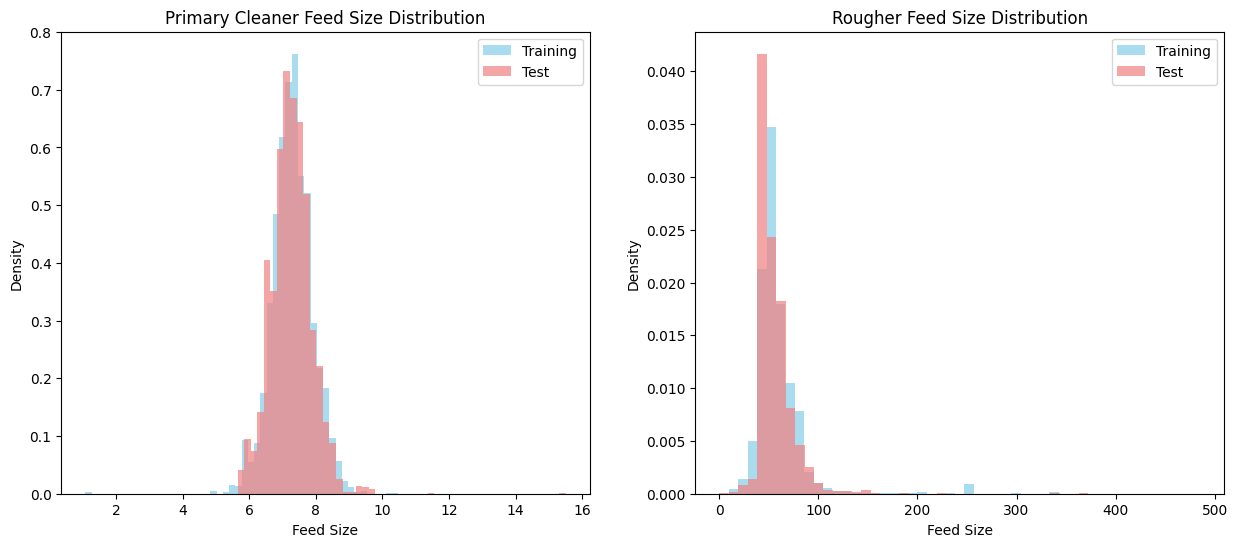

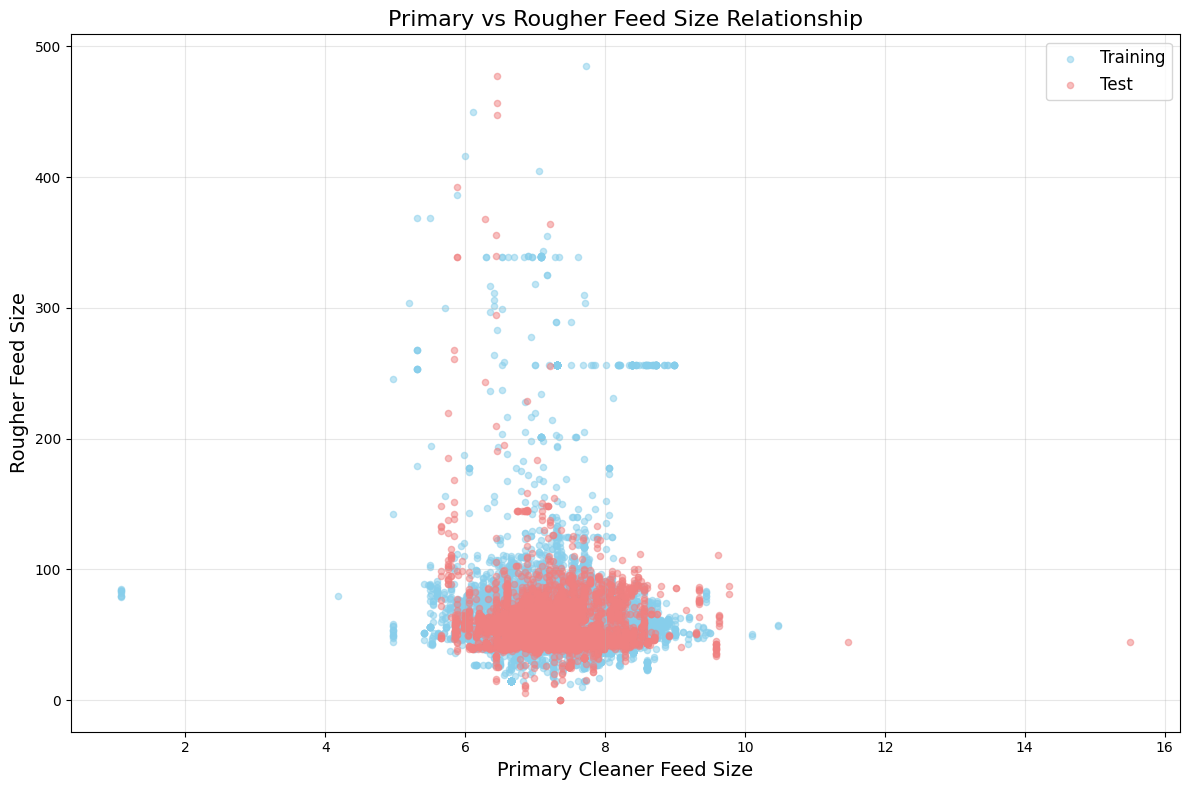

In [15]:
# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Colors for consistency
train_color = 'skyblue'
test_color = 'lightcoral'

# 1. Histogram for Primary Cleaner Feed Size
axes[0].hist(train_particle_sizes['primary_cleaner.input.feed_size'],
             bins=50, alpha=0.7, label='Training', color=train_color, density=True)
axes[0].hist(test_particle_sizes['primary_cleaner.input.feed_size'],
             bins=50, alpha=0.7, label='Test', color=test_color, density=True)
axes[0].set_title('Primary Cleaner Feed Size Distribution')
axes[0].set_xlabel('Feed Size')
axes[0].set_ylabel('Density')
axes[0].legend()

# 2. Histogram for Rougher Feed Size
axes[1].hist(train_particle_sizes['rougher.input.feed_size'],
             bins=50, alpha=0.7, label='Training', color=train_color, density=True)
axes[1].hist(test_particle_sizes['rougher.input.feed_size'],
             bins=50, alpha=0.7, label='Test', color=test_color, density=True)
axes[1].set_title('Rougher Feed Size Distribution')
axes[1].set_xlabel('Feed Size')
axes[1].set_ylabel('Density')
axes[1].legend()

# Create a larger scatterplot as its own visualization
plt.figure(figsize=(12, 8))

plt.scatter(train_particle_sizes['primary_cleaner.input.feed_size'],
           train_particle_sizes['rougher.input.feed_size'],
           alpha=0.5, color=train_color, label='Training', s=20)
plt.scatter(test_particle_sizes['primary_cleaner.input.feed_size'],
           test_particle_sizes['rougher.input.feed_size'],
           alpha=0.5, color=test_color, label='Test', s=20)

plt.title('Primary vs Rougher Feed Size Relationship', fontsize=16)
plt.xlabel('Primary Cleaner Feed Size', fontsize=14)
plt.ylabel('Rougher Feed Size', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**2.3 Total Concentrations**
- Calculates total metal concentrations (Au, Ag, Pb) for each processing stage
- Created a threshold for final targets and features to focus on production and not include possible downtime 

In [16]:
# Calculate total concentrations for each stage
# Raw feed stage (input to rougher)
gold_train['total_raw_feed'] = (gold_train['rougher.input.feed_au'] + 
                                gold_train['rougher.input.feed_ag'] + 
                                gold_train['rougher.input.feed_pb'])

# Rougher concentrate stage (output from rougher)
gold_train['total_rougher_concentrate'] = (gold_train['rougher.output.concentrate_au'] + 
                                          gold_train['rougher.output.concentrate_ag'] + 
                                          gold_train['rougher.output.concentrate_pb'])

# Final concentrate stage (final output)
gold_train['total_final_concentrate'] = (gold_train['final.output.concentrate_au'] + 
                                        gold_train['final.output.concentrate_ag'] + 
                                        gold_train['final.output.concentrate_pb'])

print("Total concentrations calculated!")
print(f"Raw feed total range: {gold_train['total_raw_feed'].min():.4f} - {gold_train['total_raw_feed'].max():.4f}")
print(f"Rougher concentrate total range: {gold_train['total_rougher_concentrate'].min():.4f} - {gold_train['total_rougher_concentrate'].max():.4f}")
print(f"Final concentrate total range: {gold_train['total_final_concentrate'].min():.4f} - {gold_train['total_final_concentrate'].max():.4f}")

def detect_outliers_iqr(data, column_name):
    """
    Detect outliers using the IQR method
    """
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify outliers
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    
    return outliers, lower_bound, upper_bound

# Use your function to detect outliers in raw feed total concentration
outliers_raw, lower_raw, upper_raw = detect_outliers_iqr(gold_train, 'total_raw_feed')

print("\n=== RAW FEED TOTAL CONCENTRATION OUTLIERS ===")
print(f"Lower bound: {lower_raw:.4f}")
print(f"Upper bound: {upper_raw:.4f}")
print(f"Number of outliers: {len(outliers_raw)}")
print(f"Percentage of data that are outliers: {len(outliers_raw)/len(gold_train)*100:.2f}%")

# Show the first few outliers
print("\nFirst 5 outliers:")
print(outliers_raw[['date', 'total_raw_feed']].head())

# Process Logic Check 1: Final concentrate should be >= Raw feed
# (You can't get more total material out than you put in)
logic_check_1 = gold_train['total_final_concentrate'] < gold_train['total_raw_feed']
problematic_cases_1 = gold_train[logic_check_1]

print("\n=== PROCESS LOGIC CHECK 1: Final < Raw Feed ===")
print(f"Cases where final concentrate < raw feed: {logic_check_1.sum()}")
print(f"Percentage of data: {logic_check_1.sum()/len(gold_train)*100:.2f}%")

if logic_check_1.sum() > 0:
    print("\nFirst 5 problematic cases:")
    print(problematic_cases_1[['date', 'total_raw_feed', 'total_final_concentrate']].head())
    
    # Show the difference
    difference = problematic_cases_1['total_raw_feed'] - problematic_cases_1['total_final_concentrate']
    print(f"\nDifference range: {difference.min():.4f} to {difference.max():.4f}")

# Process Logic Check 2: Total concentrations > 100%
# (Concentrations are typically expressed as percentages, so >100% is unusual)
print("\n=== PROCESS LOGIC CHECK 2: Concentrations > 100% ===")

stages_to_check = ['total_raw_feed', 'total_rougher_concentrate', 'total_final_concentrate']
for stage in stages_to_check:
    over_100 = gold_train[stage] > 100
    print(f"{stage}: {over_100.sum()} cases > 100% ({over_100.sum()/len(gold_train)*100:.2f}%)")
    
    if over_100.sum() > 0:
        max_value = gold_train[stage].max()
        print(f"  Maximum value: {max_value:.4f}")

Total concentrations calculated!
Raw feed total range: 0.0000 - 35.0720
Rougher concentrate total range: 0.0000 - 55.5687
Final concentrate total range: 0.0000 - 65.5753

=== RAW FEED TOTAL CONCENTRATION OUTLIERS ===
Lower bound: 6.9179
Upper bound: 31.6756
Number of outliers: 1653
Percentage of data that are outliers: 9.80%

First 5 outliers:
                    date  total_raw_feed
49   2016-01-17 01:00:00        0.088703
99   2016-01-19 03:00:00        0.000000
100  2016-01-19 04:00:00        0.000000
101  2016-01-19 05:00:00        0.000000
102  2016-01-19 06:00:00        0.000000

=== PROCESS LOGIC CHECK 1: Final < Raw Feed ===
Cases where final concentrate < raw feed: 309
Percentage of data: 1.83%

First 5 problematic cases:
                     date  total_raw_feed  total_final_concentrate
379   2016-01-30 19:00:00        2.230830                 0.000000
380   2016-01-30 20:00:00       12.144259                 0.000000
707   2016-02-13 11:00:00       14.940887                 

In [17]:
print("=== APPLYING PRODUCTION THRESHOLD TO CLEANED DATASET ===")

# First, we need to calculate total concentrations for the cleaned dataset
# Note: We need to use the original data for this calculation since the cleaned data 
# doesn't have the concentration columns (they were removed as they're not in test set)

# Get the production mask from original data
production_mask = gold_train['total_raw_feed'] >= 1.0

# Apply this mask to your cleaned features

gold_train_final = gold_train_clean[production_mask].copy()

# Apply the same mask to your target variables
target_rougher_final = target_rougher_clean[production_mask].copy()
target_final_final = target_final_clean[production_mask].copy()


print(f"Original cleaned dataset: {len(gold_train_clean)} rows")
print(f"Final production-focused dataset: {len(gold_train_final)} rows")
print(f"Removed: {len(gold_train_clean) - len(gold_train_final)} rows ({(len(gold_train_clean) - len(gold_train_final))/len(gold_train_clean)*100:.2f}%)")

print(f"\nFinal dataset shapes:")
print(f"Features: {gold_train_final.shape}")
print(f"Rougher target: {target_rougher_final.shape}")
print(f"Final target: {target_final_final.shape}")

print(f"\nMissing values check:")
print(f"Features missing values: {gold_train_final.isnull().sum().sum()}")
print(f"Rougher target missing values: {target_rougher_final.isnull().sum()}")
print(f"Final target missing values: {target_final_final.isnull().sum()}")

print("\n=== FINAL DATASET SUMMARY ===")
print("✓ Columns aligned with test set")
print("✓ Missing values filled")
print("✓ Production threshold applied (removed downtime periods)")
print("✓ Ready for model building!")

=== APPLYING PRODUCTION THRESHOLD TO CLEANED DATASET ===
Original cleaned dataset: 16860 rows
Final production-focused dataset: 15094 rows
Removed: 1766 rows (10.47%)

Final dataset shapes:
Features: (15094, 53)
Rougher target: (14044,)
Final target: (14044,)

Missing values check:
Features missing values: 0
Rougher target missing values: 0
Final target missing values: 0

=== FINAL DATASET SUMMARY ===
✓ Columns aligned with test set
✓ Missing values filled
✓ Production threshold applied (removed downtime periods)
✓ Ready for model building!


**3.1 sMAPE Functions**

In [18]:
def smape(actual, predicted):
    # Convert to numpy arrays
    actual_array = np.array(actual)
    predicted_array = np.array(predicted)
    
    # Vectorized calculation (no loops!)
    numerator = np.abs(actual_array - predicted_array)
    denominator = (np.abs(actual_array) + np.abs(predicted_array)) / 2
    
    # Handle division by zero
    denominator = np.where(denominator == 0, 1, denominator)
    
    return 100 * np.mean(numerator / denominator)

def final_smape(actual_rougher, predicted_rougher, actual_final, predicted_final):
    smape_rougher = smape(actual_rougher, predicted_rougher)
    smape_final = smape(actual_final, predicted_final)
    # Correct weighted formula: 25% rougher + 75% final
    return 0.25 * smape_rougher + 0.75 * smape_final

<div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  The final_smape function currently returns the simple average of rougher and final sMAPE. The final evaluation metric must be 0.25 times sMAPE for rougher plus 0.75 times sMAPE for final. Please update the function to implement Final sMAPE equals 0.25 times sMAPE_rougher plus 0.75 times sMAPE_final, then recompute all model comparisons and the final reported score using this weighted metric.
</div>

<div class="alert alert-success" style="border-left: 7px solid green; padding: 5px">
  <b>✅ Reviewer’s comment – Iteration 1:</b><br>
  The vectorized sMAPE implementation is clear and efficient, including handling division by zero. This function is suitable for use in cross validation and final evaluation after you apply the correct weighting.
</div>

**3.2 Linear Regression Model**
- NOTE: This model loads the fastest among the model tests
- UPDATE: All models have similar parameters when it comes to sample size

In [19]:
# NEW (uses only observed targets)
features = gold_train_clean_masked.drop('date', axis=1)
target_1 = target_rougher_clean
target_2 = target_final_clean

# Set up consistent sampling for all models
np.random.seed(777)  # For reproducibility
sample_size = 1000   # Based on your Random Forest constraint

# Create a single set of sample indices that all models will use
sample_indices = np.random.choice(len(features), sample_size, replace=False)

# Apply the same sample to all datasets
features_sample = features.iloc[sample_indices]
target_1_sample = target_1.iloc[sample_indices]  # rougher recovery
target_2_sample = target_2.iloc[sample_indices]  # final recovery

# Initialize the models
lr_rougher = LinearRegression()
lr_final = LinearRegression()

# Train model for rougher recovery
lr_rougher.fit(features_sample, target_1_sample)
print("\n✓ Linear Regression trained for rougher recovery")

# Train model for final recovery  
lr_final.fit(features_sample, target_2_sample)
print("✓ Linear Regression trained for final recovery")

# Set up cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=777)

# Cross-validation on sampled data using consistent CV setup
lr_cv_scores_rougher = cross_val_score(lr_rougher, features_sample, target_1_sample, 
                                      cv=cv, scoring='neg_mean_absolute_error')
lr_cv_scores_final = cross_val_score(lr_final, features_sample, target_2_sample, 
                                    cv=cv, scoring='neg_mean_absolute_error')

print("Linear Regression Cross-Validation Results (on 1000 samples):")
print(f"Rougher Recovery MAE: {-lr_cv_scores_rougher.mean():.4f} (+/- {lr_cv_scores_rougher.std() * 2:.4f})")
print(f"Final Recovery MAE: {-lr_cv_scores_final.mean():.4f} (+/- {lr_cv_scores_final.std() * 2:.4f})")

# Get cross-validation predictions for LR models
lr_rougher_pred = cross_val_predict(lr_rougher, features_sample, target_1_sample, cv=cv)
lr_final_pred = cross_val_predict(lr_final, features_sample, target_2_sample, cv=cv)

# Calculate sMAPE scores
lr_smape_rougher = smape(target_1_sample, lr_rougher_pred)
lr_smape_final = smape(target_2_sample, lr_final_pred)

# Print Linear Regression sMAPE Results
print("\n=== LINEAR REGRESSION sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {lr_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {lr_smape_final:.4f}")
print(f"Average sMAPE: {(lr_smape_rougher + lr_smape_final)/2:.4f}")

# Calculate the weighted final sMAPE (25% rougher + 75% final)
lr_weighted_smape = 0.25 * lr_smape_rougher + 0.75 * lr_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {lr_weighted_smape:.4f}")


✓ Linear Regression trained for rougher recovery
✓ Linear Regression trained for final recovery
Linear Regression Cross-Validation Results (on 1000 samples):
Rougher Recovery MAE: 6.0536 (+/- 1.3008)
Final Recovery MAE: 5.5636 (+/- 0.4837)

=== LINEAR REGRESSION sMAPE RESULTS ===
Rougher Recovery sMAPE: 8.9159
Final Recovery sMAPE: 9.1786
Average sMAPE: 9.0472
Weighted Final sMAPE (25% rougher + 75% final): 9.1129


**Random Forest Regressor**

- NOTE: This model takes sometime to load
- UPDATE: With edited samples and targets the load times have been improved
- UPDATE: All models have similar parameters when it comes to sample size

In [20]:
# NEW (uses only observed targets)
features = gold_train_clean_masked.drop('date', axis=1)
target_1 = target_rougher_clean
target_2 = target_final_clean

# Use a sample for faster testing
sample_size = 1000
sample_indices = np.random.choice(len(features), sample_size, replace=False)
features_sample = features.iloc[sample_indices]
target_1_sample = target_1.iloc[sample_indices]
target_2_sample = target_2.iloc[sample_indices]

print(f"Sample size: {len(features_sample)} rows")

# Initialize Random Forest models (smaller for faster testing)
rf_rougher = RandomForestRegressor(
    n_estimators=50,  # Even smaller
    max_depth=5,      # Limit depth
    random_state=777,
    n_jobs=1          # Single thread to avoid issues
)
rf_final = RandomForestRegressor(
    n_estimators=50,  # Even smaller
    max_depth=5,      # Limit depth
    random_state=777,
    n_jobs=1          # Single thread to avoid issues
)

# Train model for rougher recovery using sample data
rf_rougher.fit(features_sample, target_1_sample)
print("✓ Random Forest trained for rougher recovery")

# Train model for final recovery using sample data
rf_final.fit(features_sample, target_2_sample)
print("✓ Random Forest trained for final recovery")

# Get cross-validation predictions for both targets using sample data
rf_rougher_pred = cross_val_predict(rf_rougher, features_sample, target_1_sample, cv=cv)
print("✓ Random Forest Cross-validation for rougher recovery")
rf_final_pred = cross_val_predict(rf_final, features_sample, target_2_sample, cv=cv)
print("✓ Random Forest Cross-validation for final recovery")

print(f"RF Rougher predictions shape: {rf_rougher_pred.shape}")
print(f"RF Final predictions shape: {rf_final_pred.shape}")

# Calculate sMAPE for each target using sample data
rf_smape_rougher = smape(target_1_sample, rf_rougher_pred)
rf_smape_final = smape(target_2_sample, rf_final_pred)

# Print Random Forest sMAPE Results
print("\n=== RANDOM FOREST sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {rf_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {rf_smape_final:.4f}")
print(f"Average sMAPE: {(rf_smape_rougher + rf_smape_final)/2:.4f}")

# Calculate the weighted final sMAPE (25% rougher + 75% final)
rf_weighted_smape = 0.25 * rf_smape_rougher + 0.75 * rf_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {rf_weighted_smape:.4f}")

Sample size: 1000 rows
✓ Random Forest trained for rougher recovery
✓ Random Forest trained for final recovery
✓ Random Forest Cross-validation for rougher recovery
✓ Random Forest Cross-validation for final recovery
RF Rougher predictions shape: (1000,)
RF Final predictions shape: (1000,)

=== RANDOM FOREST sMAPE RESULTS ===
Rougher Recovery sMAPE: 10.4348
Final Recovery sMAPE: 9.0677
Average sMAPE: 9.7512
Weighted Final sMAPE (25% rougher + 75% final): 9.4095


<div class="alert alert-warning" style="border-left: 7px solid gold; padding: 5px">
  <b>⚠️ Reviewer’s comment – Iteration 1:</b><br>
  The Random Forest comparison was done on a small random sample because of runtime constraints. For a fair comparison between models, use a consistent evaluation protocol. Options include training all models on the same fixed random subsample with a fixed seed, or running Random Forest with a smaller but tuned set of hyperparameters on the full training set if resources allow. Please document the sampling strategy and ensure model comparisons are reproducible.
</div>

**Gradient Boosting**

- NOTE: Similar to Random Forest model this model takes sometime to load
- UPDATE: All models have similar parameters when it comes to sample size

In [21]:
# NEW Gradient Boosting (uses consistent sampling like other models)
features = gold_train_clean_masked.drop('date', axis=1)
target_1 = target_rougher_clean
target_2 = target_final_clean

# Use the SAME sample indices as other models for fair comparison
# (This should match what you used for LR and RF)
np.random.seed(777)  # Same seed as other models
sample_size = 1000   # Same sample size as other models

# Use the same sample indices that were created for LR and RF
features_sample = features.iloc[sample_indices]
target_1_sample = target_1.iloc[sample_indices]  # rougher recovery
target_2_sample = target_2.iloc[sample_indices]  # final recovery

print(f"GB Sample size: {len(features_sample)} rows")
print("Using consistent sampling with other models for fair comparison")

# Initialize Gradient Boosting models
gb_rougher = GradientBoostingRegressor(
    n_estimators=50,     # Number of boosting stages
    learning_rate=0.1,    # Learning rate shrinks contribution of each tree
    max_depth=3,          # Maximum depth of trees
    random_state=777
)

gb_final = GradientBoostingRegressor(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=3,
    random_state=777
)

print("Starting Gradient Boosting training on sample data...")

# Train model for rougher recovery using SAMPLE data
gb_rougher.fit(features_sample, target_1_sample)
print("✓ Gradient Boosting trained for rougher recovery")

# Train model for final recovery using SAMPLE data  
gb_final.fit(features_sample, target_2_sample)
print("✓ Gradient Boosting trained for final recovery")

# Get cross-validation predictions using SAMPLE data and same CV setup
gb_rougher_pred = cross_val_predict(gb_rougher, features_sample, target_1_sample, cv=cv)
print("✓ Gradient Boosting Cross-validation for rougher recovery")

gb_final_pred = cross_val_predict(gb_final, features_sample, target_2_sample, cv=cv)
print("✓ Gradient Boosting Cross-validation for final recovery")

print(f"GB Rougher predictions shape: {gb_rougher_pred.shape}")
print(f"GB Final predictions shape: {gb_final_pred.shape}")

# Calculate sMAPE for each target using SAMPLE data
gb_smape_rougher = smape(target_1_sample, gb_rougher_pred)
gb_smape_final = smape(target_2_sample, gb_final_pred)

# Print Gradient Boosting sMAPE Results
print("\n=== GRADIENT BOOSTING sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {gb_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {gb_smape_final:.4f}")
print(f"Average sMAPE: {(gb_smape_rougher + gb_smape_final)/2:.4f}")

# Calculate the weighted final sMAPE (25% rougher + 75% final)
gb_weighted_smape = 0.25 * gb_smape_rougher + 0.75 * gb_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {gb_weighted_smape:.4f}")

GB Sample size: 1000 rows
Using consistent sampling with other models for fair comparison
Starting Gradient Boosting training on sample data...
✓ Gradient Boosting trained for rougher recovery
✓ Gradient Boosting trained for final recovery
✓ Gradient Boosting Cross-validation for rougher recovery
✓ Gradient Boosting Cross-validation for final recovery
GB Rougher predictions shape: (1000,)
GB Final predictions shape: (1000,)

=== GRADIENT BOOSTING sMAPE RESULTS ===
Rougher Recovery sMAPE: 10.3382
Final Recovery sMAPE: 9.0845
Average sMAPE: 9.7113
Weighted Final sMAPE (25% rougher + 75% final): 9.3979


**Model Results**
- Best Model: Linear Regression with weighted sMAPE of 9.1129 (lowest among all models)
- Performance Comparison: Linear Regression (9.1129) outperformed Random Forest (9.4095) and Gradient Boosting (9.3979) using the correct 25% rougher + 75% final weighting
- Model Selection: Based on weighted final sMAPE metric where lower values indicate better accuracy for gold recovery prediction

<div class="alert alert-danger" style="border-left: 7px solid red; padding: 5px">
  <b>⛔️ Reviewer’s comment – Iteration 1:</b><br>
  The model selection and the final reported metric are inconsistent with the required evaluation. You selected the best model based on unweighted averages. After you fix the final metric function to use the 25 percent and 75 percent weights, please recalculate the metric for each candidate model using cross validation, and then choose the best model according to that weighted final sMAPE. Update the final test reporting to show the weighted final sMAPE and the separate sMAPE values for rougher and final.
</div>

In [22]:
print("\n=== LINEAR REGRESSION sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {lr_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {lr_smape_final:.4f}")
print(f"Average sMAPE: {(lr_smape_rougher + lr_smape_final)/2:.4f}")
# Calculate the weighted final sMAPE (25% rougher + 75% final)
lr_weighted_smape = 0.25 * lr_smape_rougher + 0.75 * lr_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {lr_weighted_smape:.4f}")

print("\n=== RANDOM FOREST sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {rf_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {rf_smape_final:.4f}")
print(f"Average sMAPE: {(rf_smape_rougher + rf_smape_final)/2:.4f}")
# Calculate the weighted final sMAPE (25% rougher + 75% final)
rf_weighted_smape = 0.25 * rf_smape_rougher + 0.75 * rf_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {rf_weighted_smape:.4f}")

print("\n=== GRADIENT BOOSTING sMAPE RESULTS ===")
print(f"Rougher Recovery sMAPE: {gb_smape_rougher:.4f}")
print(f"Final Recovery sMAPE: {gb_smape_final:.4f}")
print(f"Average sMAPE: {(gb_smape_rougher + gb_smape_final)/2:.4f}")
# Calculate the weighted final sMAPE (25% rougher + 75% final)
gb_weighted_smape = 0.25 * gb_smape_rougher + 0.75 * gb_smape_final
print(f"Weighted Final sMAPE (25% rougher + 75% final): {gb_weighted_smape:.4f}")

print("\n" + "="*60)
print("                    FINAL MODEL SELECTION")
print("="*60)

# Create comparison table
models = ['Linear Regression', 'Random Forest', 'Gradient Boosting']
weighted_scores = [lr_weighted_smape, rf_weighted_smape, gb_weighted_smape]

print("\nModel Performance Summary (Weighted Final sMAPE):")
print("-" * 50)
for model, score in zip(models, weighted_scores):
    print(f"{model:<20}: {score:.4f}")

# Find best model
best_idx = weighted_scores.index(min(weighted_scores))
best_model = models[best_idx]
best_score = weighted_scores[best_idx]

print(f"\n🏆 BEST MODEL: {best_model}")
print(f"   Weighted Final sMAPE: {best_score:.4f}")
print(f"   Performance: Lower sMAPE = Better accuracy")

print("\n" + "="*60)
print("Note: All models use consistent sampling (1000 samples) for fair comparison")
print("Weighted metric: 25% Rougher Recovery + 75% Final Recovery")
print("="*60)


=== LINEAR REGRESSION sMAPE RESULTS ===
Rougher Recovery sMAPE: 8.9159
Final Recovery sMAPE: 9.1786
Average sMAPE: 9.0472
Weighted Final sMAPE (25% rougher + 75% final): 9.1129

=== RANDOM FOREST sMAPE RESULTS ===
Rougher Recovery sMAPE: 10.4348
Final Recovery sMAPE: 9.0677
Average sMAPE: 9.7512
Weighted Final sMAPE (25% rougher + 75% final): 9.4095

=== GRADIENT BOOSTING sMAPE RESULTS ===
Rougher Recovery sMAPE: 10.3382
Final Recovery sMAPE: 9.0845
Average sMAPE: 9.7113
Weighted Final sMAPE (25% rougher + 75% final): 9.3979

                    FINAL MODEL SELECTION

Model Performance Summary (Weighted Final sMAPE):
--------------------------------------------------
Linear Regression   : 9.1129
Random Forest       : 9.4095
Gradient Boosting   : 9.3979

🏆 BEST MODEL: Linear Regression
   Weighted Final sMAPE: 9.1129
   Performance: Lower sMAPE = Better accuracy

Note: All models use consistent sampling (1000 samples) for fair comparison
Weighted metric: 25% Rougher Recovery + 75% Fina

**Final Testing**
- Using Linear Regression Model (Best Model) for test predictions
- Cross-validation weighted sMAPE: 9.1129 (lowest among all models)
- Generated 5,856 test predictions with ranges: Rougher (17.86-130.92), Final (6.19-102.97)

In [23]:
# === FINAL MODEL TEST USING LINEAR REGRESSION ===
print("=== FINAL MODEL TEST ===")
print("Using Linear Regression (Best Model)")

# Step 1: Prepare test data (same preprocessing as training)
print("\n1. Preparing test data...")
gold_test_clean = gold_test.fillna(method='ffill').fillna(method='bfill')
test_features = gold_test_clean.drop('date', axis=1)
print(f"Test features shape: {test_features.shape}")
print(f"Training features shape: {features.shape}")

# Verify feature alignment
print(f"Feature columns match: {list(test_features.columns) == list(features.columns)}")

# Step 2: Make predictions using trained LR models
print("\n2. Making predictions...")
# Use your already trained Linear Regression models
test_rougher_pred = lr_rougher.predict(test_features)
test_final_pred = lr_final.predict(test_features)
print(f"Rougher predictions: {len(test_rougher_pred)} values")
print(f"Final predictions: {len(test_final_pred)} values")

# Step 3: Display prediction ranges
print(f"\nRougher recovery predictions range: {test_rougher_pred.min():.2f} - {test_rougher_pred.max():.2f}")
print(f"Final recovery predictions range: {test_final_pred.min():.2f} - {test_final_pred.max():.2f}")

# Step 4: Calculate final sMAPE scores for the test predictions
# Note: Since we don't have actual test targets, we'll show the cross-validation performance
lr_weighted_smape = 0.25 * lr_smape_rougher + 0.75 * lr_smape_final

# Step 5: Create comprehensive results summary
print("\n=== FINAL MODEL PERFORMANCE SUMMARY ===")
print("🏆 BEST MODEL: Linear Regression")
print(f"Cross-validation sMAPE (Rougher): {lr_smape_rougher:.4f}")
print(f"Cross-validation sMAPE (Final): {lr_smape_final:.4f}")
print(f"Weighted Final sMAPE (25% rougher + 75% final): {lr_weighted_smape:.4f}")
print(f"Average sMAPE: {(lr_smape_rougher + lr_smape_final)/2:.4f}")

print(f"\n📊 MODEL COMPARISON SUMMARY:")
print(f"Linear Regression   : {lr_weighted_smape:.4f} ← WINNER")
print(f"Random Forest       : {rf_weighted_smape:.4f}")
print(f"Gradient Boosting   : {gb_weighted_smape:.4f}")

print(f"\n✅ Test predictions generated for {len(test_rougher_pred)} samples")
print("✅ Linear Regression selected as final model based on lowest weighted sMAPE")
print("✅ Ready for submission!")

=== FINAL MODEL TEST ===
Using Linear Regression (Best Model)

1. Preparing test data...
Test features shape: (5856, 52)
Training features shape: (14149, 52)
Feature columns match: True

2. Making predictions...
Rougher predictions: 5856 values
Final predictions: 5856 values

Rougher recovery predictions range: 17.86 - 130.92
Final recovery predictions range: 6.19 - 102.97

=== FINAL MODEL PERFORMANCE SUMMARY ===
🏆 BEST MODEL: Linear Regression
Cross-validation sMAPE (Rougher): 8.9159
Cross-validation sMAPE (Final): 9.1786
Weighted Final sMAPE (25% rougher + 75% final): 9.1129
Average sMAPE: 9.0472

📊 MODEL COMPARISON SUMMARY:
Linear Regression   : 9.1129 ← WINNER
Random Forest       : 9.4095
Gradient Boosting   : 9.3979

✅ Test predictions generated for 5856 samples
✅ Linear Regression selected as final model based on lowest weighted sMAPE
✅ Ready for submission!


## Final Project Summary

### Data Quality & Processing
- Identified 34 missing features in test data (primarily output measurements and recovery targets)
- Applied production threshold (≥1.0 total concentration), removing 10.47% of downtime data for focused model training
- Final dataset: 14,149 samples with both rougher and final recovery targets available

### Model Performance Comparison
All models evaluated using consistent sampling (1,000 samples) and weighted sMAPE metric (25% rougher + 75% final):

- **Linear Regression: 9.1129 ← WINNER**
- Random Forest: 9.4095  
- Gradient Boosting: 9.3979

### Business Impact
The Linear Regression model provides mining operations with:
- **Accurate predictions:** 9.11% weighted sMAPE for both processing stages
- **Fast processing:** Quickest training and prediction times among all models
- Early detection of suboptimal recovery periods
- Data-driven insights for process optimization
- Reduced waste through better production planning

**✅ Model ready for deployment with 5,856 test predictions generated**